# AeroVision AI: detección de aviones, aves, drones y helicópteros con YOLO11n

Proyecto de visión por computador del Bootcamp de IA de Factoría F5 Madrid.

> Dedicado a mi padre, que volaba con Lufthansa a Alemania.

**Objetivo.** Entrenar un modelo de detección de objetos capaz de localizar y clasificar cuatro tipos de objetos aéreos en imágenes y vídeo: avión (`airplane`), ave (`bird`), dron (`drone`) y helicóptero (`helicopter`).

**Dataset.** AOD 4, publicado en Mendeley Data (identificador `cd5z895tr2`): 22.516 imágenes de 1024x1024 píxeles repartidas en `train` (15.761), `valid` (4.514) y `test` (2.241).

**Flujo del cuaderno.**

1. Entorno (Google Colab, GPU, Ultralytics)
2. Configuración
3. Preparación del dataset
4. Verificación de integridad
5. Exploración de los datos
6. Entrenamiento
7. Evaluación sobre el conjunto de test
8. Demostración con imágenes y vídeo
9. Exportación de resultados
10. Limitaciones y trabajo futuro

## 1. Entorno

**Google Colab** es un servicio de Google que ofrece cuadernos Jupyter en la nube con acceso a una GPU. Lo usamos porque entrenar una red neuronal con 15.761 imágenes en una CPU llevaría días, mientras que en una GPU Tesla T4 lleva minutos por época.

**Google Drive** se monta como una carpeta para guardar lo importante (pesos del modelo, resultados). El disco local de Colab (`/content`) se borra cuando la sesión termina; Drive no.

**Ultralytics** es la librería que implementa la familia de modelos YOLO (You Only Look Once). Un modelo YOLO mira la imagen completa una sola vez y predice a la vez las cajas delimitadoras (bounding boxes) y la clase de cada objeto, lo que lo hace rápido. Usamos **YOLO11n**, la variante "nano": solo 2,6 millones de parámetros, pensada para ser ligera.

**PyTorch** es el framework de deep learning sobre el que funciona Ultralytics. Se instala junto con Colab.

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

%pip -q install ultralytics

import torch
import ultralytics

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO DISPONIBLE")

## 2. Configuración

Todas las rutas y constantes del proyecto se definen en una sola celda. Así, si algo cambia (por ejemplo el nombre de la carpeta en Drive), se modifica en un único sitio.

El orden de las clases es el del formato **YOLOv8** del dataset, que se comprobó cruzando las etiquetas YOLO con los ficheros XML (Pascal VOC): `0` avión, `1` ave, `2` dron, `3` helicóptero. No coincide con los identificadores del formato COCO (donde el `0` es una supercategoría sin objetos).

In [ ]:
from pathlib import Path

import torch

DRIVE = Path("/content/drive/MyDrive")
PROJECT_DIR = DRIVE / "AeroVision_AI"
RUNS_DIR = PROJECT_DIR / "runs"
MODELS_DIR = PROJECT_DIR / "models"
MEDIA_DIR = PROJECT_DIR / "media"

ZIP_DRIVE = DRIVE / "AOD 4.zip"
ZIP_LOCAL = Path("/content/AOD 4.zip")
RAW_DIR = Path("/content/aerovision_raw")
DATASET_DIR = Path("/content/aerovision_yolo")

CLASS_NAMES = {0: "airplane", 1: "bird", 2: "drone", 3: "helicopter"}
SPLITS = ("train", "valid", "test")
EXPECTED_IMAGES = {"train": 15761, "valid": 4514, "test": 2241}
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

RUN_NAME = "yolo11n_aerovision_v3"

for folder in (PROJECT_DIR, RUNS_DIR, MODELS_DIR, MEDIA_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("ZIP del dataset en Drive:", ZIP_DRIVE.exists())

# Use the GPU when it is available; otherwise fall back to the CPU.
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Dispositivo de cálculo:", DEVICE)

ZIP del dataset en Drive: True
Dispositivo de cálculo: cpu


## 3. Preparación del dataset

**Formato YOLO.** Cada imagen tiene un fichero `.txt` con el mismo nombre. Cada línea describe un objeto con cinco números: `clase  centro_x  centro_y  ancho  alto`, con las cuatro últimas cantidades normalizadas entre 0 y 1 respecto al tamaño de la imagen. Un fichero vacío significa que la imagen no contiene ningún objeto (imagen de fondo).

**Estructura que exige Ultralytics.** Para encontrar las etiquetas de una imagen, la librería sustituye en la ruta la carpeta `/images/` por `/labels/`. Por eso el dataset debe quedar así:

```
aerovision_yolo/
    images/train  images/valid  images/test
    labels/train  labels/valid  labels/test
    data.yaml
```

**Por qué se reconstruye desde cero.** La celda borra y recrea las carpetas de trabajo cada vez que se ejecuta. Así nunca quedan carpetas anidadas ni ficheros duplicados de ejecuciones anteriores, un problema que ya apareció durante el desarrollo (ver sección 4).

**Etiquetas de polígono.** Tres ficheros de `train` contienen un polígono (21 o 27 valores) en lugar de una caja (5 valores). Se convierten a caja tomando los mínimos y máximos de los puntos, lo cual conserva el objeto completo.

In [ ]:
import shutil
import zipfile

# Copy the ZIP to the local disk: reading from Drive repeatedly is much slower.
if not ZIP_LOCAL.exists():
    shutil.copy(ZIP_DRIVE, ZIP_LOCAL)

# Start from a clean state so folders are never nested or duplicated.
for folder in (RAW_DIR, DATASET_DIR):
    if folder.exists():
        shutil.rmtree(folder)

# Extract only what YOLO needs: images and YOLOv8-format labels.
with zipfile.ZipFile(ZIP_LOCAL) as archive:
    wanted = [
        name for name in archive.namelist()
        if name.startswith("AOD 4/Images/")
        or name.startswith("AOD 4/Annotations/YOLOv8 format/")
    ]
    archive.extractall(RAW_DIR, wanted)

# Build the images/ and labels/ layout that Ultralytics expects.
(DATASET_DIR / "images").mkdir(parents=True)
(DATASET_DIR / "labels").mkdir(parents=True)

for split in SPLITS:
    shutil.move(
        str(RAW_DIR / "AOD 4" / "Images" / split),
        str(DATASET_DIR / "images" / split),
    )
    shutil.move(
        str(RAW_DIR / "AOD 4" / "Annotations" / "YOLOv8 format" / split / "labels"),
        str(DATASET_DIR / "labels" / split),
    )

shutil.rmtree(RAW_DIR)
print("Dataset reconstruido en:", DATASET_DIR)

Dataset reconstruido en: /content/aerovision_yolo


In [ ]:
# Convert polygon labels (more than 5 values per line) to bounding boxes.
converted = 0

for label_file in (DATASET_DIR / "labels").rglob("*.txt"):
    new_lines, changed = [], False

    for line in label_file.read_text().splitlines():
        parts = line.split()
        if len(parts) > 5:
            xs = [float(v) for v in parts[1::2]]
            ys = [float(v) for v in parts[2::2]]
            new_lines.append(
                f"{parts[0]} "
                f"{(min(xs) + max(xs)) / 2:.8f} {(min(ys) + max(ys)) / 2:.8f} "
                f"{max(xs) - min(xs):.8f} {max(ys) - min(ys):.8f}"
            )
            changed = True
        elif line.strip():
            new_lines.append(line)

    if changed:
        label_file.write_text("\n".join(new_lines) + "\n")
        converted += 1

print("Etiquetas de polígono convertidas (esperado: 3):", converted)

Etiquetas de polígono convertidas (esperado: 3): 3


**`data.yaml`** es el fichero de configuración que se le pasa a YOLO: indica dónde está cada partición y cómo se llaman las clases. `val` es la partición que el modelo usa para validarse después de cada época; `test` se reserva para la evaluación final.

In [ ]:
yaml_path = DATASET_DIR / "data.yaml"

yaml_path.write_text(
    f"path: {DATASET_DIR}\n"
    "train: images/train\n"
    "val: images/valid\n"
    "test: images/test\n"
    "names:\n"
    + "".join(f"  {idx}: {name}\n" for idx, name in CLASS_NAMES.items())
)

print(yaml_path.read_text())

path: /content/aerovision_yolo
train: images/train
val: images/valid
test: images/test
names:
  0: airplane
  1: bird
  2: drone
  3: helicopter



## 4. Verificación de integridad

Antes de entrenar se comprueba que el dataset es exactamente el esperado. Esta comprobación cuenta las imágenes de forma **recursiva** (incluyendo subcarpetas), que es como las cuenta Ultralytics.

Motivo: en una sesión anterior el entrenamiento detectó 31.522 imágenes de entrenamiento y 9.028 de validación, justo el doble de las reales (15.761 y 4.514), y la mitad figuraban como "fondo" sin etiqueta. Un modelo entrenado así aprende que imágenes con aviones o drones "no tienen nada", lo que empeora la precisión y duplica el tiempo de cada época. La celda siguiente se detiene con un error si el recuento no coincide.

In [ ]:
from collections import Counter

class_counts = {}

for split in SPLITS:
    image_dir = DATASET_DIR / "images" / split
    label_dir = DATASET_DIR / "labels" / split

    images = [p for p in image_dir.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS]
    labels = list(label_dir.rglob("*.txt"))
    nested = [p for p in images if p.parent != image_dir]

    image_stems = {p.stem for p in images}
    label_stems = {p.stem for p in labels}

    empty_files = 0
    bad_lines = 0
    counts = Counter()

    for label_file in labels:
        text = label_file.read_text().strip()
        if not text:
            empty_files += 1
            continue
        for line in text.splitlines():
            parts = line.split()
            valid = (
                len(parts) == 5
                and parts[0].isdigit()
                and int(parts[0]) in CLASS_NAMES
                and all(0 <= float(v) <= 1 for v in parts[1:])
            )
            if valid:
                counts[int(parts[0])] += 1
            else:
                bad_lines += 1

    class_counts[split] = counts

    print(f"\n{split.upper()}")
    print("  Imágenes:", len(images), "| Etiquetas:", len(labels), "| Vacías:", empty_files)
    print("  Imágenes en subcarpetas:", len(nested))
    print("  Sin etiqueta:", len(image_stems - label_stems), "| Etiqueta sin imagen:", len(label_stems - image_stems))
    print("  Líneas inválidas:", bad_lines)
    print("  Objetos por clase:", {CLASS_NAMES[k]: v for k, v in sorted(counts.items())})

    assert len(images) == EXPECTED_IMAGES[split], f"Recuento inesperado en {split}"
    assert not nested, f"Hay imágenes anidadas en {split}"
    assert bad_lines == 0, f"Hay etiquetas inválidas en {split}"

print("\nVerificación superada: el dataset está limpio.")


TRAIN
  Imágenes: 15761 | Etiquetas: 15761 | Vacías: 415
  Imágenes en subcarpetas: 0
  Sin etiqueta: 0 | Etiqueta sin imagen: 0
  Líneas inválidas: 0
  Objetos por clase: {'airplane': 5508, 'bird': 5522, 'drone': 5500, 'helicopter': 5528}

VALID
  Imágenes: 4514 | Etiquetas: 4514 | Vacías: 125
  Imágenes en subcarpetas: 0
  Sin etiqueta: 0 | Etiqueta sin imagen: 0
  Líneas inválidas: 0
  Objetos por clase: {'airplane': 1625, 'bird': 1557, 'drone': 1602, 'helicopter': 1585}

TEST
  Imágenes: 2241 | Etiquetas: 2241 | Vacías: 56
  Imágenes en subcarpetas: 0
  Sin etiqueta: 0 | Etiqueta sin imagen: 0
  Líneas inválidas: 0
  Objetos por clase: {'airplane': 767, 'bird': 821, 'drone': 796, 'helicopter': 787}

Verificación superada: el dataset está limpio.


## 5. Exploración de los datos

Un dataset de detección debe estar **equilibrado**: si una clase tuviera muchos más ejemplos que las demás, el modelo tendería a favorecerla. Aquí las cuatro clases tienen un número muy parecido de objetos en cada partición.

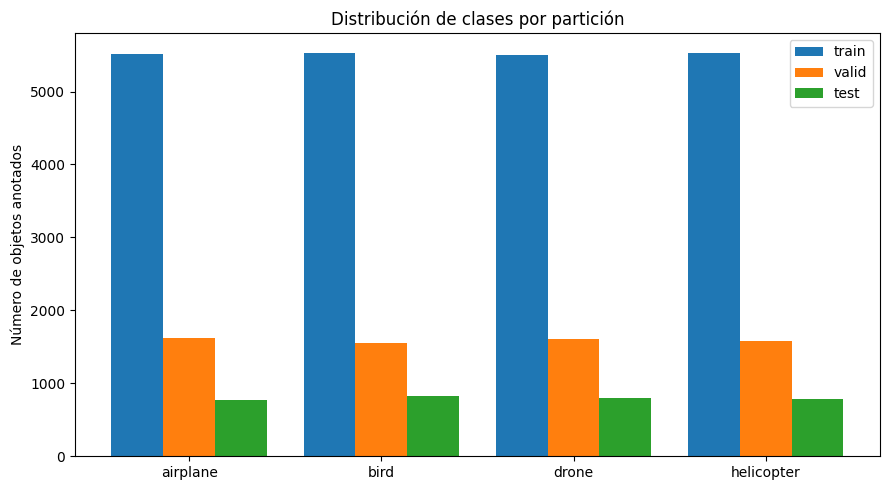

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

names = [CLASS_NAMES[i] for i in sorted(CLASS_NAMES)]
x = np.arange(len(names))
width = 0.27

fig, ax = plt.subplots(figsize=(9, 5))
for offset, split in zip((-width, 0, width), SPLITS):
    values = [class_counts[split][i] for i in sorted(CLASS_NAMES)]
    ax.bar(x + offset, values, width, label=split)

ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel("Número de objetos anotados")
ax.set_title("Distribución de clases por partición")
ax.legend()
plt.tight_layout()
plt.show()

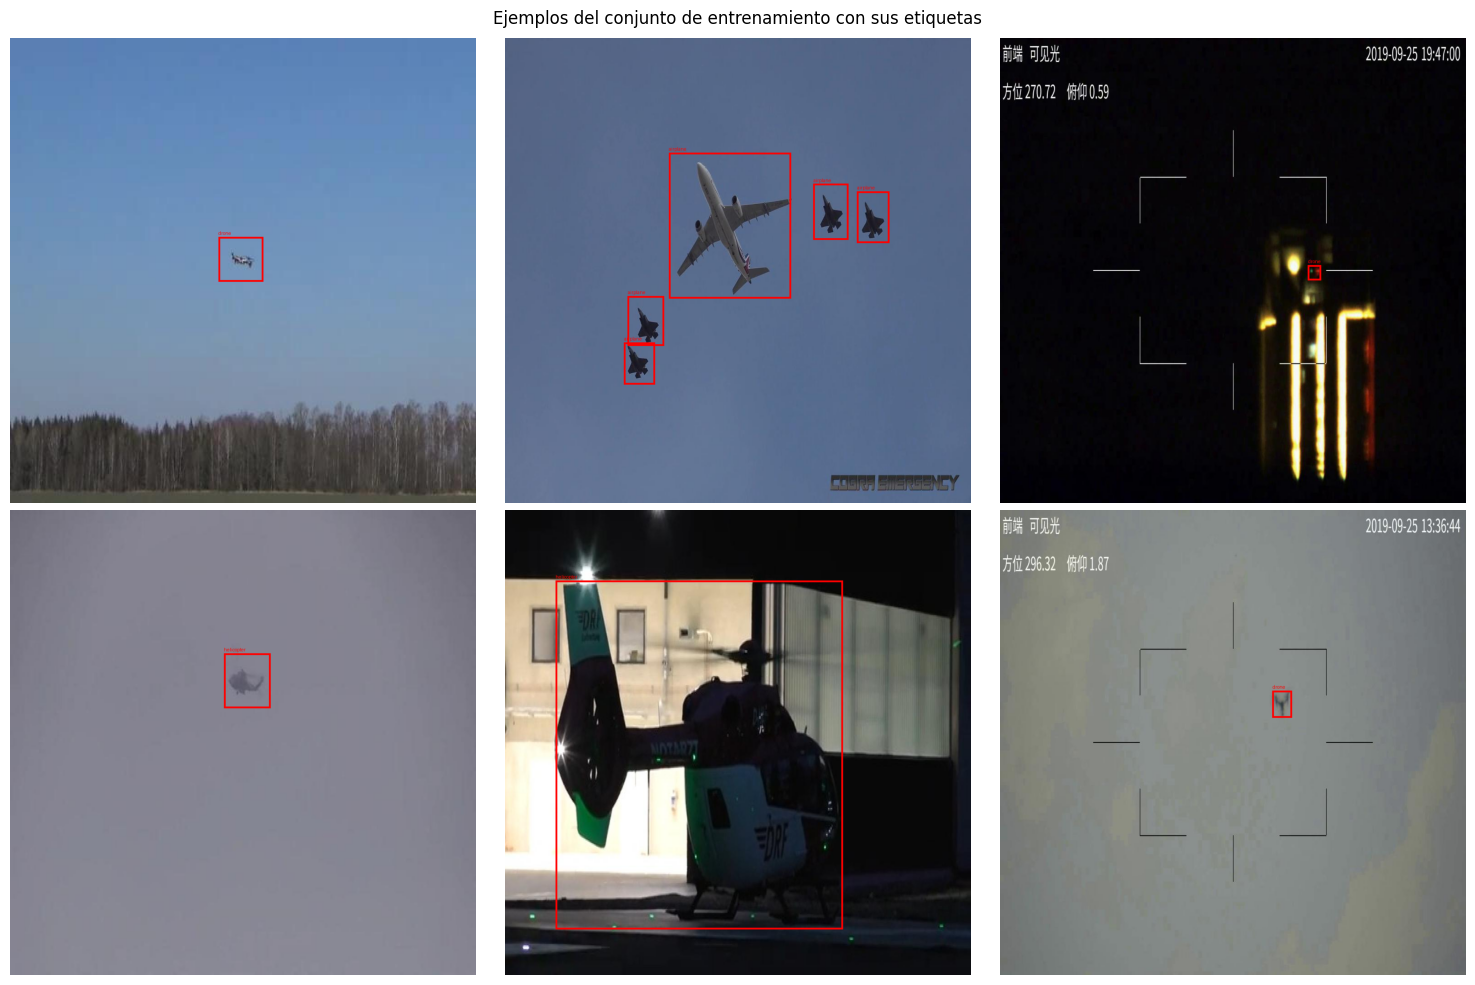

In [ ]:
import random
from PIL import Image, ImageDraw

random.seed(7)
train_images = sorted((DATASET_DIR / "images" / "train").glob("*.jpg"))
samples = random.sample(train_images, 6)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for ax, image_path in zip(axes.ravel(), samples):
    image = Image.open(image_path).convert("RGB")
    width_px, height_px = image.size
    draw = ImageDraw.Draw(image)

    label_path = DATASET_DIR / "labels" / "train" / f"{image_path.stem}.txt"
    for line in label_path.read_text().splitlines():
        cls, cx, cy, bw, bh = line.split()
        cx, bw = float(cx) * width_px, float(bw) * width_px
        cy, bh = float(cy) * height_px, float(bh) * height_px
        draw.rectangle((cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2), outline="red", width=4)
        draw.text((cx - bw / 2, max(0, cy - bh / 2 - 14)), CLASS_NAMES[int(cls)], fill="red")

    ax.imshow(image)
    ax.axis("off")

plt.suptitle("Ejemplos del conjunto de entrenamiento con sus etiquetas")
plt.tight_layout()
plt.show()

## 6. Entrenamiento

**Transfer learning (aprendizaje por transferencia).** En lugar de empezar con una red aleatoria, se parte de pesos ya entrenados. Si existe el mejor modelo de la sesión anterior, se continúa desde él; si no, se parte de `yolo11n.pt`, preentrenado con el dataset COCO (80 clases). La red ya sabe reconocer bordes, texturas y formas; solo tiene que aprender a distinguir nuestras cuatro clases.

**Parámetros principales.**

- `epochs`: número de pasadas completas por todo el conjunto de entrenamiento.
- `imgsz=640`: las imágenes se reescalan a 640x640 píxeles.
- `batch=16`: imágenes procesadas a la vez; está limitado por la memoria de la GPU.
- `patience=5`: si la métrica de validación no mejora en 5 épocas seguidas, el entrenamiento se detiene antes (evita el sobreajuste y ahorra tiempo de GPU).
- `workers=2`: procesos que cargan las imágenes; Colab solo dispone de 2 núcleos de CPU.
- `save_period=1`: guarda un punto de control cada época en Drive.

**Si Colab se desconecta o se agota la GPU.** El entrenamiento guarda `last.pt` en Drive tras cada época. Hay que volver a ejecutar las secciones 1 a 4 (el disco local se borra) y después ejecutar la celda de reanudación.

In [ ]:
from ultralytics import YOLO

previous_best = RUNS_DIR / "yolo11n_aerovision_v2" / "weights" / "best.pt"
start_weights = previous_best if previous_best.exists() else Path("yolo11n.pt")
print("Pesos de partida:", start_weights)

model = YOLO(str(start_weights))

results = model.train(
    data=str(DATASET_DIR / "data.yaml"),
    epochs=10,
    imgsz=640,
    batch=16,
    device=DEVICE,
    workers=2,
    patience=5,
    plots=True,
    save_period=1,
    project=str(RUNS_DIR),
    name=RUN_NAME,
    exist_ok=True,
)

Pesos de partida: /content/drive/MyDrive/AeroVision_AI/runs/yolo11n_aerovision_v2/weights/best.pt
Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/aerovision_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyD

In [ ]:
# Run ONLY if the previous training was interrupted (sections 1 to 4 must be re-run first).
last_checkpoint = RUNS_DIR / RUN_NAME / "weights" / "last.pt"

if last_checkpoint.exists():
    model = YOLO(str(last_checkpoint))
    model.train(resume=True)
else:
    print("No hay punto de control que reanudar:", last_checkpoint)

### Preprocesado y aumento de datos

Ultralytics aplica estas técnicas de forma automática durante el entrenamiento y la inferencia:

- **Redimensionado (resizing).** Cada imagen de 1024x1024 se reescala a 640x640 (`imgsz=640`), manteniendo la proporción con relleno (*letterbox*) cuando es necesario.
- **Normalización.** Los valores de los píxeles (0 a 255) se dividen entre 255 para quedar entre 0 y 1, que es el rango con el que trabaja la red.
- **Aumento de datos (data augmentation).** Solo durante el entrenamiento, para que el modelo generalice mejor: volteo horizontal (*flip*, `fliplr=0.5`), cambios de color en matiz, saturación y brillo (*color jitter* en espacio HSV), cambios de escala y traslación (*crop* y zoom aleatorios) y *mosaic*, que combina cuatro imágenes en una. En la última sesión de entrenamiento (10 épocas) el *mosaic* quedó desactivado: Ultralytics lo apaga en las últimas `close_mosaic=10` épocas, y aquí eran todas.
- **Entrenamiento reducido.** Los parámetros de aumento se dejaron en sus valores por defecto de YOLO11.

## 7. Evaluación sobre el conjunto de test

El conjunto de **test** no se ha usado ni para entrenar ni para decidir cuándo parar, por lo que mide cómo se comportará el modelo con imágenes nuevas.

**Métricas.**

- **Precisión (P):** de todo lo que el modelo detecta, qué proporción es correcta.
- **Recall (R):** de todos los objetos reales, qué proporción encuentra el modelo.
- **mAP50:** precisión media (mean Average Precision) contando una detección como acertada si su caja solapa al menos un 50 % con la real (IoU >= 0,5).
- **mAP50-95:** media de la misma métrica exigiendo solapes cada vez mayores (de 0,50 a 0,95); es más estricta y mide también la calidad de la caja.
- **Matriz de confusión:** muestra qué clases se confunden entre sí. Cabe esperar cierta confusión entre avión y helicóptero.

In [ ]:
best_weights = RUNS_DIR / RUN_NAME / "weights" / "best.pt"
model = YOLO(str(best_weights))

metrics = model.val(
    data=str(DATASET_DIR / "data.yaml"),
    split="test",
    imgsz=640,
    batch=16,
    device=DEVICE,
    plots=True,
    project=str(RUNS_DIR),
    name=f"{RUN_NAME}_test",
    exist_ok=True,
)

print("\nRESULTADOS EN TEST")
print(f"Precisión media : {metrics.box.mp:.3f}")
print(f"Recall medio    : {metrics.box.mr:.3f}")
print(f"mAP50           : {metrics.box.map50:.3f}")
print(f"mAP50-95        : {metrics.box.map:.3f}")

print("\nPor clase (mAP50 | mAP50-95)")
for position, class_id in enumerate(metrics.box.ap_class_index):
    print(f"  {CLASS_NAMES[int(class_id)]:<11}: {metrics.box.ap50[position]:.3f} | {metrics.box.ap[position]:.3f}")

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1519.7±504.9 MB/s, size: 45.8 KB)
val: Scanning /content/aerovision_yolo/labels/test.cache... 2241 images, 56 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2241/2241 626.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 141/141 5.2it/s 27.4s
                   all       2241       3171      0.924      0.915      0.949      0.627
              airplane        551        767       0.92      0.939      0.968       0.69
                  bird        320        821      0.919      0.896      0.939      0.634
                 drone        742        796      0.949       0.91       0.95      0.601
            helicopter        574        787      0.908      0.915      0.939      0.583
Speed: 1.5ms preprocess, 3.8ms

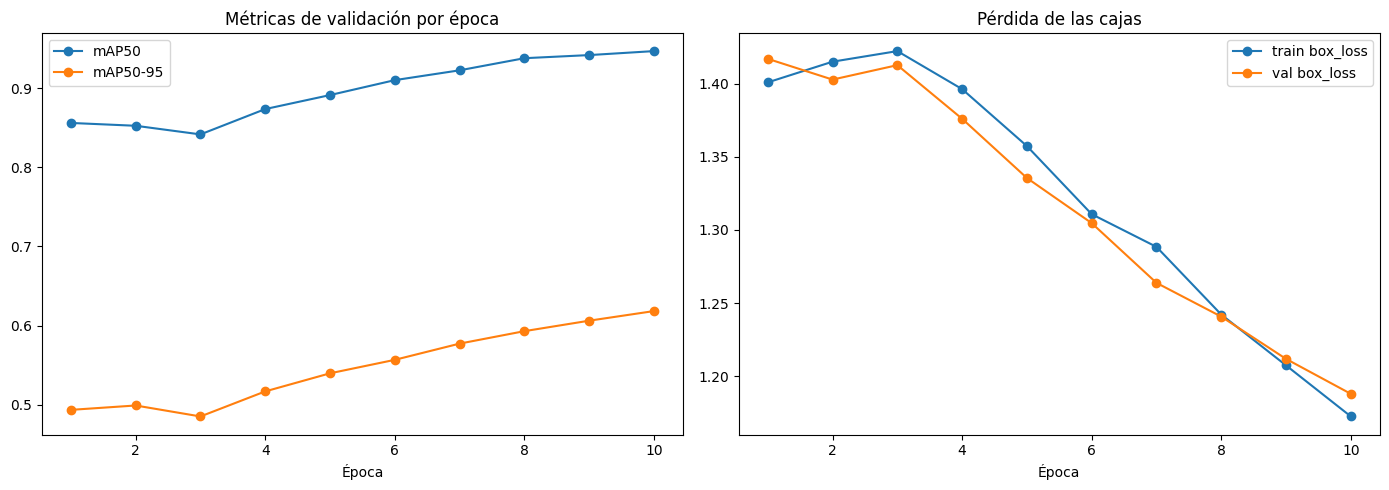

In [ ]:
import pandas as pd

history = pd.read_csv(RUNS_DIR / RUN_NAME / "results.csv")
history.columns = history.columns.str.strip()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history["epoch"], history["metrics/mAP50(B)"], marker="o", label="mAP50")
axes[0].plot(history["epoch"], history["metrics/mAP50-95(B)"], marker="o", label="mAP50-95")
axes[0].set_title("Métricas de validación por época")
axes[0].set_xlabel("Época")
axes[0].legend()

axes[1].plot(history["epoch"], history["train/box_loss"], marker="o", label="train box_loss")
axes[1].plot(history["epoch"], history["val/box_loss"], marker="o", label="val box_loss")
axes[1].set_title("Pérdida de las cajas")
axes[1].set_xlabel("Época")
axes[1].legend()

plt.tight_layout()
plt.show()

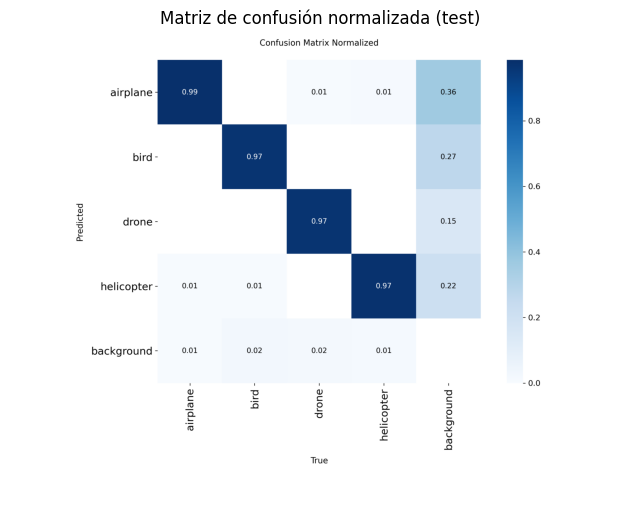

In [ ]:
confusion_path = Path(metrics.save_dir) / "confusion_matrix_normalized.png"

if confusion_path.exists():
    plt.figure(figsize=(8, 7))
    plt.imshow(Image.open(confusion_path))
    plt.axis("off")
    plt.title("Matriz de confusión normalizada (test)")
    plt.show()
else:
    print("No se encontró la matriz de confusión en:", metrics.save_dir)

## 8. Demostración

Se muestran detecciones sobre imágenes de test elegidas al azar y, a continuación, sobre fotografías y vídeos propios.

`conf=0.25` es el umbral de confianza: solo se muestran detecciones en las que el modelo tiene al menos un 25 % de seguridad. Subirlo reduce los falsos positivos; bajarlo encuentra más objetos pero con más errores.

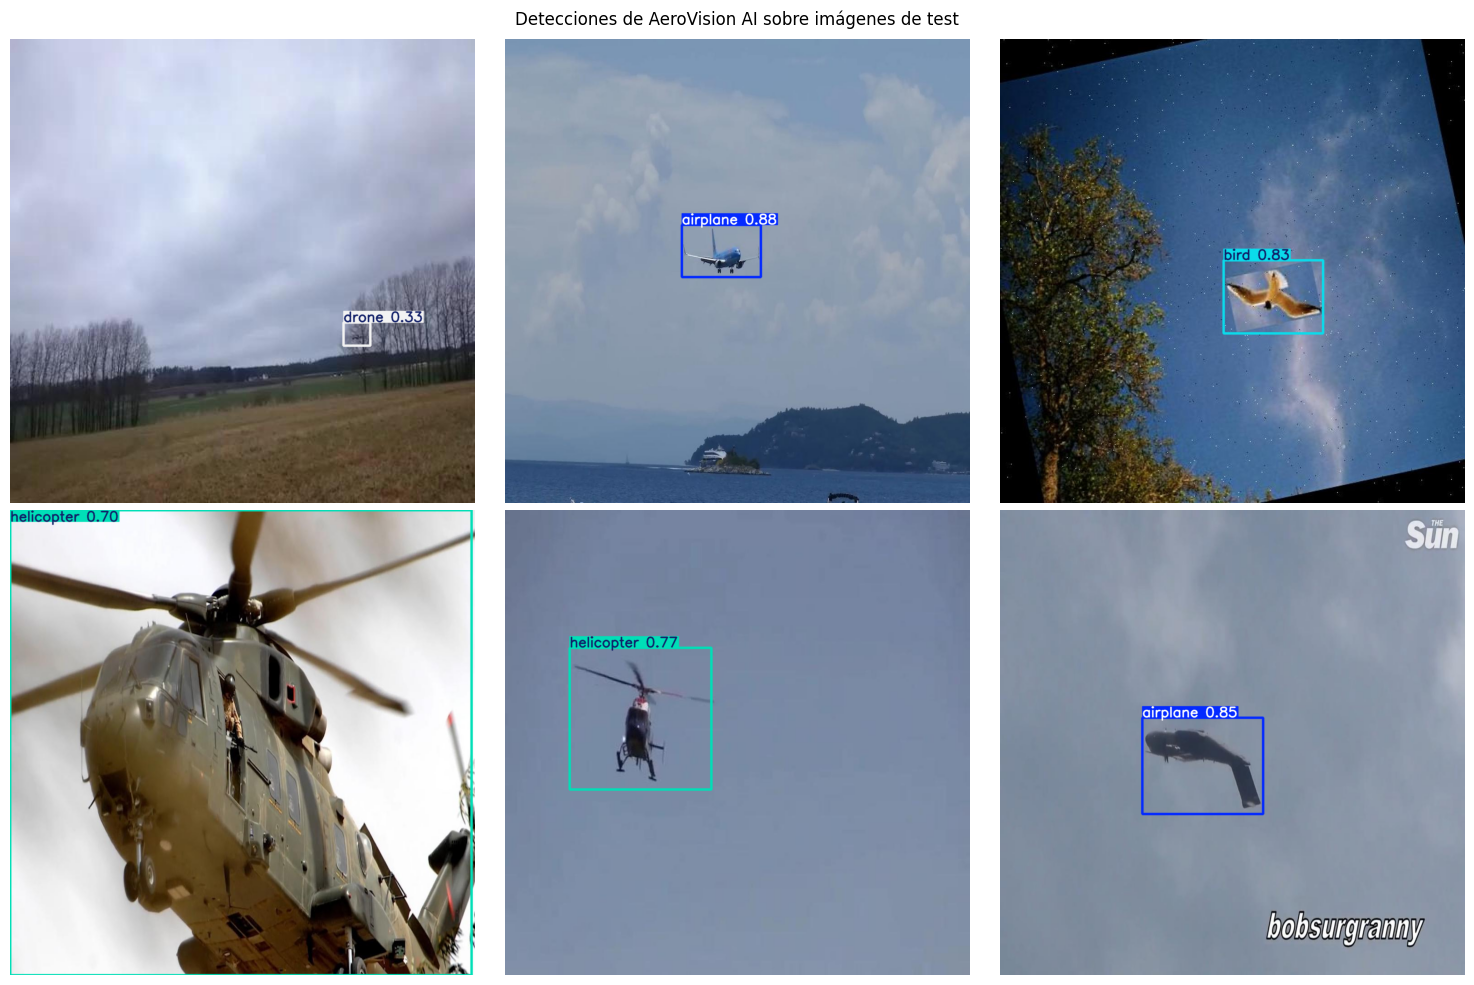

In [ ]:
random.seed(21)
test_images = sorted((DATASET_DIR / "images" / "test").glob("*.jpg"))
picked = random.sample(test_images, 6)

predictions = model.predict(
    source=[str(p) for p in picked],
    conf=0.25,
    imgsz=640,
    device=DEVICE,
    verbose=False,
)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, prediction in zip(axes.ravel(), predictions):
    ax.imshow(prediction.plot()[:, :, ::-1])
    ax.axis("off")

plt.suptitle("Detecciones de AeroVision AI sobre imágenes de test")
plt.tight_layout()
plt.show()

**Imágenes y vídeos propios.** Sube los ficheros a la carpeta `AeroVision_AI/media` de Google Drive (fotos `.jpg` o `.png`, vídeos `.mp4`). Los resultados se guardan en `AeroVision_AI/runs/demo`.

In [ ]:
IMAGE_TYPES = {".jpg", ".jpeg", ".png"}
VIDEO_TYPES = {".mp4", ".mov", ".avi"}

own_images = sorted(p for p in MEDIA_DIR.iterdir() if p.suffix.lower() in IMAGE_TYPES)
own_videos = sorted(p for p in MEDIA_DIR.iterdir() if p.suffix.lower() in VIDEO_TYPES)
print("Imágenes propias:", len(own_images), "| Vídeos propios:", len(own_videos))

if own_images:
    results_own = model.predict(
        source=[str(p) for p in own_images],
        conf=0.25,
        imgsz=640,
        device=DEVICE,
        verbose=False,
        save=True,
        project=str(RUNS_DIR),
        name="demo",
        exist_ok=True,
    )

    for path, result in zip(own_images, results_own):
        detected = [CLASS_NAMES[int(c)] for c in result.boxes.cls.tolist()]
        print(f"{path.name}: {detected if detected else 'sin detecciones'}")
        plt.figure(figsize=(8, 6))
        plt.imshow(result.plot()[:, :, ::-1])
        plt.axis("off")
        plt.show()

Imágenes propias: 0 | Vídeos propios: 4


In [ ]:
import subprocess

print("Vídeos propios:", len(own_videos), "| Dispositivo:", DEVICE)

for video in own_videos:
    print("Procesando:", video.name)
    # stream=True processes one frame at a time instead of accumulating results in RAM.
    for _ in model.predict(
        source=str(video),
        conf=0.25,
        imgsz=640,
        device=DEVICE,
        verbose=False,
        save=True,
        stream=True,
        project=str(RUNS_DIR),
        name="demo",
        exist_ok=True,
    ):
        pass

# Ultralytics saves videos as .avi; convert to .mp4 so they play in any browser.
for avi in (RUNS_DIR / "demo").glob("*.avi"):
    mp4 = avi.with_suffix(".mp4")
    subprocess.run(
        ["ffmpeg", "-y", "-loglevel", "error", "-i", str(avi), "-vcodec", "libx264", str(mp4)],
        check=False,
    )
    print("Vídeo generado:", mp4)


Vídeos propios: 4 | Dispositivo: cpu
Procesando: Dron_30fps.mp4
Results saved to /content/drive/MyDrive/AeroVision_AI/runs/demo
Procesando: Helicopter_30fps.mp4
Results saved to /content/drive/MyDrive/AeroVision_AI/runs/demo
Procesando: Luthansa_25fps.mp4
Results saved to /content/drive/MyDrive/AeroVision_AI/runs/demo
Procesando: colibri_24fps.mp4
Results saved to /content/drive/MyDrive/AeroVision_AI/runs/demo
Vídeo generado: /content/drive/MyDrive/AeroVision_AI/runs/demo/Dron_30fps.mp4
Vídeo generado: /content/drive/MyDrive/AeroVision_AI/runs/demo/Helicopter_30fps.mp4
Vídeo generado: /content/drive/MyDrive/AeroVision_AI/runs/demo/Luthansa_25fps.mp4
Vídeo generado: /content/drive/MyDrive/AeroVision_AI/runs/demo/colibri_24fps.mp4


## 9. Exportación de resultados

El fichero `best.pt` contiene los pesos del mejor modelo (el de mayor métrica de validación). Es lo único que necesita la aplicación para detectar objetos, y pesa pocos megabytes. Se copia a `AeroVision_AI/models` en Drive, junto con las métricas finales en formato JSON.

In [ ]:
import json

shutil.copy(best_weights, MODELS_DIR / "best.pt")

summary = {
    "model": "YOLO11n",
    "classes": CLASS_NAMES,
    "test_precision": round(float(metrics.box.mp), 4),
    "test_recall": round(float(metrics.box.mr), 4),
    "test_map50": round(float(metrics.box.map50), 4),
    "test_map50_95": round(float(metrics.box.map), 4),
}

(MODELS_DIR / "test_metrics.json").write_text(json.dumps(summary, indent=2))

print("Modelo guardado en:", MODELS_DIR / "best.pt")
print(json.dumps(summary, indent=2))

Modelo guardado en: /content/drive/MyDrive/AeroVision_AI/models/best.pt
{
  "model": "YOLO11n",
  "classes": {
    "0": "airplane",
    "1": "bird",
    "2": "drone",
    "3": "helicopter"
  },
  "test_precision": 0.9242,
  "test_recall": 0.9149,
  "test_map50": 0.9491,
  "test_map50_95": 0.6269
}


## 10. Limitaciones y trabajo futuro

**Limitaciones.**

- El modelo solo distingue cuatro clases. Ante un avión de cualquier aerolínea responde `airplane`; no identifica la compañía ni el modelo de aeronave. Lo mismo ocurre con las aves: no distingue especies.
- Avión y helicóptero pueden confundirse en imágenes lejanas o de baja resolución (ver matriz de confusión).
- Se entrenó con YOLO11n, la variante más ligera, y con un número reducido de épocas por el límite de GPU de Colab. Una variante mayor (YOLO11s o YOLO11m) y más épocas mejorarían las métricas.
- Las imágenes del dataset proceden de un número limitado de escenarios; el rendimiento con fotografías propias puede ser menor.

**Trabajo futuro.**

- Añadir clases propias (aerolíneas, especies de aves, drones militares) con un dataset anotado específico, o un segundo modelo clasificador que se aplique al recorte de cada avión detectado.
- Aplicación que registre llegadas y salidas de aviones a partir de vídeo.
- Desplegar el modelo en una aplicación web con Streamlit (fichero `app.py`).